# Miniprojeto 2 — Modelagem de Churn com Árvore de Decisão e XGBoost

Este notebook dá sequência ao pré-processamento (`preprocessing.ipynb`) e treina modelos para prever o cancelamento de clientes (*churn*) nos 60 dias seguintes à data-base de 21/09/2026.

**Objetivos da etapa**

- Árvore de Decisão: exploração de hiperparâmetros, pré-poda × pós-poda (`ccp_alpha`), extração de regras SE-ENTÃO e importância dos atributos.
- XGBoost: busca de hiperparâmetros com `GridSearchCV` e Optuna, e análise do trade-off entre `n_estimators` e `learning_rate`.
- Métrica principal: **recall da classe churn**, acompanhado de precisão, F1 e ROC-AUC, com análise de overfitting (gap treino × teste).

**Ordem de execução:** `EDA.ipynb` → `preprocessing.ipynb` → `modeling.ipynb`.

## 1. Bibliotecas e configurações

Fixamos uma semente única (`SEED = 42`), a mesma usada na divisão treino/teste do pré-processamento, para que todos os resultados sejam reproduzíveis.

In [1]:
import time
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline

import xgboost
import optuna
import sklearn

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

print(f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__} | optuna {optuna.__version__}")

scikit-learn 1.9.1 | xgboost 3.4.1 | optuna 5.1.0


## 2. Carga dos dados

Utilizamos os arquivos **antes da imputação** exportados pelo pré-processamento, e não os já preparados. O preenchimento de ausentes e a codificação precisam ser reaprendidos dentro de cada rodada da validação cruzada, olhando apenas a parte de treino daquela rodada; usar dados já imputados levaria estatísticas da parte de validação para o ajuste (*data leakage*).

- `id_cliente` é lido como texto e fica fora dos preditores (é só um identificador).
- `churn` é o alvo.
- Contrato e pagamento são lidos como texto para que os ausentes sejam reconhecidos pelo imputador.

In [2]:
DIRETORIO_DADOS = Path("../data/processed")
if not DIRETORIO_DADOS.exists():
    DIRETORIO_DADOS = Path("data/processed")
if not DIRETORIO_DADOS.exists():
    raise FileNotFoundError("Execute antes o preprocessing.ipynb para gerar data/processed/.")

TIPOS_LEITURA = {
    "id_cliente": "string",
    "tipo_contrato": "string",
    "forma_pagamento": "string",
}


def carregar_conjunto(nome):
    dados = pd.read_csv(DIRETORIO_DADOS / nome, dtype=TIPOS_LEITURA)
    X = dados.drop(columns=["id_cliente", "churn"])
    y = dados["churn"].astype(int)
    ids = dados["id_cliente"]
    return X, y, ids


X_treino, y_treino, ids_treino = carregar_conjunto("treino_antes_imputacao.csv")
X_teste, y_teste, ids_teste = carregar_conjunto("teste_antes_imputacao.csv")

print(f"Treino: {X_treino.shape[0]} clientes | Teste (reservado): {X_teste.shape[0]} clientes")
print(f"Preditores ({X_treino.shape[1]}): {list(X_treino.columns)}")

Treino: 3493 clientes | Teste (reservado): 1497 clientes
Preditores (8): ['mensalidade_rs', 'atrasos_6m', 'tipo_contrato', 'forma_pagamento', 'fibra_optica', 'debito_automatico', 'chamados_90d', 'tempo_cliente_meses']


### 2.1 Conferência dos dados

Verificamos o balanceamento do alvo (a estratificação deve manter a mesma proporção de churn nos dois conjuntos), os valores ausentes que o pipeline vai tratar e se nenhum cliente aparece nos dois conjuntos.

In [3]:
assert set(ids_treino).isdisjoint(ids_teste), "Cliente presente no treino e no teste"
assert X_treino.columns.equals(X_teste.columns)

distribuicao = pd.DataFrame({
    "Treino (n)": y_treino.value_counts().sort_index(),
    "Treino (%)": (y_treino.value_counts(normalize=True).sort_index() * 100).round(2),
    "Teste (n)": y_teste.value_counts().sort_index(),
    "Teste (%)": (y_teste.value_counts(normalize=True).sort_index() * 100).round(2),
})
distribuicao.index = ["Não churn (0)", "Churn (1)"]
print("--- DISTRIBUIÇÃO DO ALVO ---")
display(distribuicao)

print("--- VALORES AUSENTES (SERÃO TRATADOS DENTRO DO PIPELINE) ---")
display(pd.DataFrame({"Treino": X_treino.isna().sum(), "Teste": X_teste.isna().sum()}))

PROPORCAO_NEG_POS = (y_treino == 0).sum() / (y_treino == 1).sum()
print(f"Razão negativos/positivos no treino: {PROPORCAO_NEG_POS:.2f}")

--- DISTRIBUIÇÃO DO ALVO ---


,Treino (n),Treino (%),Teste (n),Teste (%)
Não churn (0),2253,64.5,965,64.46
Churn (1),1240,35.5,532,35.54


--- VALORES AUSENTES (SERÃO TRATADOS DENTRO DO PIPELINE) ---


,Treino,Teste
mensalidade_rs,91,41
atrasos_6m,36,7
tipo_contrato,16,9
forma_pagamento,13,7
fibra_optica,0,0
debito_automatico,0,0
chamados_90d,0,0
tempo_cliente_meses,0,0


Razão negativos/positivos no treino: 1.82


## 3. Protocolo anti-vazamento

Todos os modelos seguem as mesmas regras:

1. **Pipeline único.** Cada modelo é encadeado com uma cópia nova (`clone`) do `preprocessador_template.joblib`. Assim, imputação e codificação são ajustadas apenas nos dados de treino de cada rodada.
2. **Validação cruzada estratificada** com 5 partes (`StratifiedKFold`, `shuffle=True`, `random_state=42`), mantendo a proporção de churn em cada parte. Toda escolha de hiperparâmetros e de limiar de decisão é feita aqui.
3. **Teste intocado.** `X_teste`/`y_teste` só são usados na avaliação final, uma única vez, depois de todas as escolhas.

In [4]:
PREPROCESSADOR_TEMPLATE = joblib.load(DIRETORIO_DADOS / "preprocessador_template.joblib")

CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)


def montar_pipeline(modelo):
    """Encadeia uma cópia não ajustada do pré-processamento com o modelo."""
    return Pipeline([
        ("prep", clone(PREPROCESSADOR_TEMPLATE)),
        ("modelo", modelo),
    ])


PREPROCESSADOR_TEMPLATE

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputacao', ...), ('transformacao', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('mensalidade', ...), ('atrasos', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. 

### 3.1 Checagem do pré-processamento

Ajustamos o template no treino completo e comparamos com o `treino_preparado.csv` exportado pelo pré-processamento. Os dois precisam ser idênticos, o que confirma que o pipeline usado aqui reproduz a base tratada (entregável 3). Também conferimos que o template carregado está sem ajuste, evitando reaproveitar parâmetros aprendidos fora da validação cruzada.

In [5]:
from sklearn.utils.validation import check_is_fitted
from sklearn.exceptions import NotFittedError

try:
    check_is_fitted(PREPROCESSADOR_TEMPLATE)
    raise AssertionError("O template não deveria estar ajustado")
except NotFittedError:
    pass

prep_conferencia = clone(PREPROCESSADOR_TEMPLATE)
X_treino_conferencia = prep_conferencia.fit_transform(X_treino)

treino_exportado = pd.read_csv(DIRETORIO_DADOS / "treino_preparado.csv", dtype={"id_cliente": "string"})
treino_exportado = treino_exportado.drop(columns=["id_cliente", "churn"])

assert list(X_treino_conferencia.columns) == list(treino_exportado.columns)
np.testing.assert_allclose(
    X_treino_conferencia.to_numpy(dtype=float), treino_exportado.to_numpy(dtype=float)
)

ATRIBUTOS = list(X_treino_conferencia.columns)
print(f"Pipeline reproduz o treino_preparado.csv: {X_treino_conferencia.shape}")
print(f"Atributos após o pré-processamento: {ATRIBUTOS}")
display(X_treino_conferencia.head())

del prep_conferencia, X_treino_conferencia, treino_exportado

Pipeline reproduz o treino_preparado.csv: (3493, 8)
Atributos após o pré-processamento: ['mensalidade_rs', 'atrasos_6m', 'chamados_90d', 'tempo_cliente_meses', 'tipo_contrato', 'forma_pagamento', 'fibra_optica', 'debito_automatico']


,mensalidade_rs,atrasos_6m,chamados_90d,tempo_cliente_meses,tipo_contrato,forma_pagamento,fibra_optica,debito_automatico
0,73.33,0.0,0,21,2.0,1.0,0,1
1,69.40,1.0,1,20,2.0,0.0,0,0
2,98.76,0.0,0,15,0.0,0.0,1,0
3,92.37,0.0,2,24,2.0,2.0,1,1
4,58.78,0.0,2,51,0.0,2.0,0,0


## 4. Estratégia de avaliação

### 4.1 Por que não otimizar apenas o recall

O recall da classe churn é a métrica principal: deixar escapar um cliente que vai cancelar (falso negativo) custa mais do que oferecer retenção a quem ficaria (falso positivo). Porém, **otimizar só o recall é degenerado**: um modelo que diz "todos vão cancelar" tem recall 1,0 e não serve para nada. Por isso adotamos duas etapas:

1. **Busca de hiperparâmetros pelo F2** (`fbeta_score` com β = 2). O F2 combina precisão e recall dando **4 vezes mais peso ao recall** (β² = 4), alinhado à prioridade de negócio sem premiar o modelo trivial.
2. **Ajuste do limiar de decisão.** Em vez do corte padrão de 0,5, escolhemos o limiar que atinge um **recall-alvo de 80%** com a maior precisão possível. As probabilidades usadas nessa escolha são *out-of-fold* (cada cliente do treino é previsto por um modelo que não o viu), então o teste continua intocado.

Acompanhamos também precisão, F1, ROC-AUC, PR-AUC (`average_precision`) e acurácia, sempre na validação e no treino, para medir o gap de overfitting.

In [6]:
from sklearn.dummy import DummyClassifier
from sklearn.exceptions import UndefinedMetricWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    f1_score, fbeta_score, make_scorer, precision_recall_curve,
    precision_score, recall_score
)
from sklearn.model_selection import GridSearchCV, cross_val_predict, cross_validate
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)

F2 = make_scorer(fbeta_score, beta=2)
METRICAS = {
    "recall": "recall",
    "precision": "precision",
    "f1": "f1",
    "f2": F2,
    "roc_auc": "roc_auc",
    "pr_auc": "average_precision",
    "accuracy": "accuracy",
}
METRICA_BUSCA = "f2"
RECALL_ALVO = 0.80

RESULTADOS_CV = {}   # métricas médias da validação cruzada por modelo
LIMIARES = {}        # limiar escolhido e métricas out-of-fold por modelo


def _registrar(nome, medias_val, medias_treino, desvio_recall, tempo):
    linha = {}
    for m in METRICAS:
        linha[f"{m} (val)"] = medias_val[m]
        linha[f"{m} (treino)"] = medias_treino[m]
    linha["recall dp (val)"] = desvio_recall
    linha["tempo (s)"] = tempo
    RESULTADOS_CV[nome] = linha


def avaliar_cv(nome, pipeline):
    """Validação cruzada de um pipeline com hiperparâmetros fixos."""
    inicio = time.perf_counter()
    r = cross_validate(
        pipeline, X_treino, y_treino, cv=CV, scoring=METRICAS,
        return_train_score=True, n_jobs=-1
    )
    _registrar(
        nome,
        {m: r[f"test_{m}"].mean() for m in METRICAS},
        {m: r[f"train_{m}"].mean() for m in METRICAS},
        r["test_recall"].std(),
        time.perf_counter() - inicio,
    )


def registrar_busca(nome, busca, tempo):
    """Registra as métricas da melhor combinação de um GridSearchCV."""
    res, i = busca.cv_results_, busca.best_index_
    _registrar(
        nome,
        {m: res[f"mean_test_{m}"][i] for m in METRICAS},
        {m: res[f"mean_train_{m}"][i] for m in METRICAS},
        res["std_test_recall"][i],
        tempo,
    )


def tabela_cv(nomes=None):
    df = pd.DataFrame(RESULTADOS_CV).T.astype(float)
    if nomes is not None:
        df = df.loc[nomes]
    tabela = df[[f"{m} (val)" for m in ["recall", "precision", "f1", "f2", "roc_auc", "pr_auc"]]].copy()
    tabela["gap recall (treino-val)"] = df["recall (treino)"] - df["recall (val)"]
    tabela["gap acurácia (treino-val)"] = df["accuracy (treino)"] - df["accuracy (val)"]
    tabela["tempo (s)"] = df["tempo (s)"]
    return tabela.round(3)

### 4.2 Ajuste do limiar de decisão

A função abaixo gera probabilidades *out-of-fold* no treino, percorre todos os limiares possíveis e escolhe o de **maior precisão entre os que garantem recall ≥ 80%**. O limiar escolhido aqui será o mesmo aplicado no teste, na avaliação final.

In [7]:
def escolher_limiar(nome, pipeline, recall_alvo=RECALL_ALVO, plotar=True):
    proba = cross_val_predict(
        pipeline, X_treino, y_treino, cv=CV, method="predict_proba", n_jobs=-1
    )[:, 1]
    precisao, recall, limiares = precision_recall_curve(y_treino, proba)
    precisao, recall = precisao[:-1], recall[:-1]

    candidatos = np.where(recall >= recall_alvo, precisao, -1)
    limiar = limiares[np.argmax(candidatos)]

    pred = (proba >= limiar).astype(int)
    pred_05 = (proba >= 0.5).astype(int)
    LIMIARES[nome] = {
        "limiar": limiar,
        "recall (limiar)": recall_score(y_treino, pred),
        "precisão (limiar)": precision_score(y_treino, pred),
        "F1 (limiar)": f1_score(y_treino, pred),
        "F2 (limiar)": fbeta_score(y_treino, pred, beta=2),
        "recall (0,5)": recall_score(y_treino, pred_05),
        "precisão (0,5)": precision_score(y_treino, pred_05),
    }

    if plotar:
        fig, eixo = plt.subplots(figsize=(7, 4))
        eixo.plot(limiares, precisao, label="Precisão")
        eixo.plot(limiares, recall, label="Recall")
        eixo.axvline(limiar, color="red", linestyle="--", label=f"Limiar escolhido = {limiar:.3f}")
        eixo.axhline(recall_alvo, color="gray", linestyle=":", label=f"Recall-alvo = {recall_alvo:.0%}")
        eixo.set_xlabel("Limiar de probabilidade")
        eixo.set_title(f"Precisão e recall out-of-fold × limiar — {nome}")
        eixo.legend(loc="lower left")
        plt.tight_layout()
        plt.show()

    return limiar, proba


def tabela_limiares(nomes=None):
    df = pd.DataFrame(LIMIARES).T.astype(float)
    return (df.loc[nomes] if nomes is not None else df).round(3)

### 4.3 Modelos de referência (baselines)

Antes das árvores, medimos três referências com o mesmo protocolo:

- **Sempre "não churn"**: acurácia de ~64,5% e recall zero. Mostra por que acurácia engana em bases desbalanceadas.
- **Sempre "churn"**: recall 1,0 com precisão igual à prevalência (~35,5%). É o modelo degenerado que o F2 evita premiar.
- **Regressão logística** (com padronização e `class_weight="balanced"`): referência linear simples. Qualquer árvore precisa superá-la para justificar a complexidade.

In [8]:
avaliar_cv("Dummy: sempre não churn", montar_pipeline(DummyClassifier(strategy="most_frequent")))
avaliar_cv("Dummy: sempre churn", montar_pipeline(DummyClassifier(strategy="constant", constant=1)))
avaliar_cv("Regressão logística", montar_pipeline(Pipeline([
    ("escala", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
])))

print("--- BASELINES (MÉDIA DA VALIDAÇÃO CRUZADA, 5 PARTES) ---")
display(tabela_cv())

--- BASELINES (MÉDIA DA VALIDAÇÃO CRUZADA, 5 PARTES) ---


,recall (val),precision (val),f1 (val),f2 (val),roc_auc (val),pr_auc (val),gap recall (treino-val),gap acurácia (treino-val),tempo (s)
Dummy: sempre não churn,0.000,0.000,0.000,0.000,0.500,0.355,0.000,0.000,7.880
Dummy: sempre churn,1.000,0.355,0.524,0.733,0.500,0.355,0.000,-0.000,6.590
Regressão logística,0.729,0.583,0.648,0.694,0.798,0.670,0.006,0.004,6.463


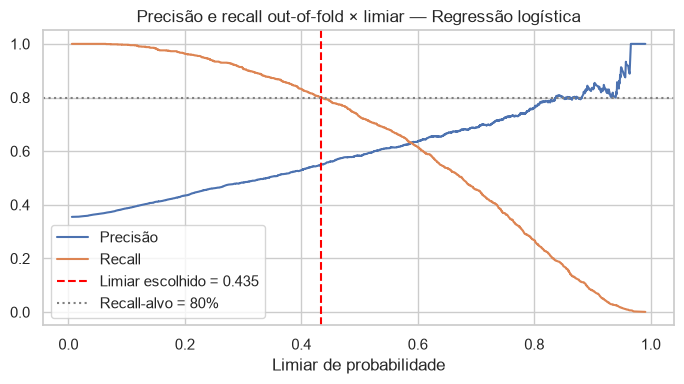

,limiar,recall (limiar),precisão (limiar),F1 (limiar),F2 (limiar),"recall (0,5)","precisão (0,5)"
Regressão logística,0.435,0.801,0.55,0.652,0.734,0.729,0.583


In [9]:
LIMIAR_LR, _ = escolher_limiar("Regressão logística", montar_pipeline(Pipeline([
    ("escala", StandardScaler()),
    ("lr", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED)),
])))
display(tabela_limiares())

## 5. Módulo 1 — Árvore de Decisão

Seguimos quatro etapas: (5.1) árvore sem restrições, para observar o overfitting; (5.2) **pré-poda**, limitando o crescimento durante o treino; (5.3) **pós-poda** por complexidade de custo (`ccp_alpha`), podando uma árvore completa; e (5.4) comparação entre as abordagens. Depois extraímos as regras (5.5) e a importância dos atributos (5.6).

### 5.1 Árvore sem restrições

Sem limites, a árvore cresce até isolar cada cliente do treino. Esperamos desempenho quase perfeito no treino e bem pior na validação: é a memorização de ruído que a poda deve corrigir.

In [10]:
from sklearn.tree import DecisionTreeClassifier, plot_tree

avaliar_cv("AD sem restrições", montar_pipeline(DecisionTreeClassifier(random_state=SEED)))

ad_livre = montar_pipeline(DecisionTreeClassifier(random_state=SEED)).fit(X_treino, y_treino)
print(f"Profundidade: {ad_livre[-1].get_depth()} | Folhas: {ad_livre[-1].get_n_leaves()}")
display(tabela_cv(["Regressão logística", "AD sem restrições"]))

Profundidade: 25 | Folhas: 932


,recall (val),precision (val),f1 (val),f2 (val),roc_auc (val),pr_auc (val),gap recall (treino-val),gap acurácia (treino-val),tempo (s)
Regressão logística,0.729,0.583,0.648,0.694,0.798,0.670,0.006,0.004,6.463
AD sem restrições,0.492,0.501,0.496,0.494,0.611,0.427,0.507,0.354,0.493


### 5.2 Pré-poda (parada antecipada)

A busca é feita em **duas etapas** com `GridSearchCV` (5 partes, critério de escolha F2), para explorar mais hiperparâmetros sem uma grade combinatória gigante.

**Etapa A: hiperparâmetros estruturais.** Justificativa das faixas: o treino tem 3.493 clientes, com cerca de 2.800 em cada rodada da validação.

| Hiperparâmetro | Valores | Justificativa |
|---|---|---|
| `max_depth` | 2, 3, 4, 5, 6, 8, 10, None | Com 8 atributos, profundidades acima de ~10 já isolam grupos minúsculos; 2–4 favorecem regras legíveis. |
| `min_samples_leaf` | 1, 5, 10, 20, 50, 100 | Folhas com ≥ 20 clientes (~0,7% do treino) dão taxas de churn estáveis; 100 testa um regime bem conservador. |
| `min_samples_split` | 2, 20, 50 | Impede divisões de nós pequenos. |
| `criterion` | gini, entropy | As duas medidas de impureza clássicas (`log_loss` equivale a `entropy` no sklearn). |
| `class_weight` | None, balanced | Hiperparâmetro extra: `balanced` dá aos churners peso ~1,8× maior que aos não churners e desloca as divisões a favor do recall. |

**Etapa B: refinamento.** Fixamos o melhor da etapa A e testamos os demais hiperparâmetros do enunciado e outros extras: `max_leaf_nodes`, `min_impurity_decrease`, `max_features` e `splitter`. Os valores padrão estão incluídos na grade, então a etapa B nunca piora o resultado da etapa A.

In [11]:
grade_pre_a = {
    "modelo__max_depth": [2, 3, 4, 5, 6, 8, 10, None],
    "modelo__min_samples_leaf": [1, 5, 10, 20, 50, 100],
    "modelo__min_samples_split": [2, 20, 50],
    "modelo__criterion": ["gini", "entropy"],
    "modelo__class_weight": [None, "balanced"],
}

busca_pre_a = GridSearchCV(
    montar_pipeline(DecisionTreeClassifier(random_state=SEED)),
    grade_pre_a, scoring=METRICAS, refit=METRICA_BUSCA, cv=CV,
    n_jobs=-1, return_train_score=True
)
inicio = time.perf_counter()
busca_pre_a.fit(X_treino, y_treino)
tempo_pre_a = time.perf_counter() - inicio

n_comb_a = len(busca_pre_a.cv_results_["params"])
print(f"Etapa A: {n_comb_a} combinações × 5 partes = {n_comb_a * 5} ajustes em {tempo_pre_a:.1f} s")
print(f"Melhor F2 (val): {busca_pre_a.best_score_:.4f}")
print("Melhores hiperparâmetros:", {k.replace("modelo__", ""): v for k, v in busca_pre_a.best_params_.items()})


def top_combinacoes(busca, n=10):
    res = pd.DataFrame(busca.cv_results_)
    colunas = [c for c in res.columns if c.startswith("param_")]
    tabela = res[colunas + ["mean_test_f2", "mean_test_recall", "mean_test_precision",
                            "mean_train_f2", "rank_test_f2"]]
    tabela = tabela.rename(columns=lambda c: c.replace("param_modelo__", ""))
    return tabela.sort_values("rank_test_f2").head(n).round(4)


display(top_combinacoes(busca_pre_a))

Etapa A: 576 combinações × 5 partes = 2880 ajustes em 108.4 s
Melhor F2 (val): 0.7191
Melhores hiperparâmetros: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}


,class_weight,criterion,max_depth,min_samples_leaf,min_samples_split,mean_test_f2,mean_test_recall,mean_test_precision,mean_train_f2,rank_test_f2
319,balanced,gini,3,50,20,0.7191,0.8073,0.5016,0.7336,1
320,balanced,gini,3,50,50,0.7191,0.8073,0.5016,0.7336,1
308,balanced,gini,3,1,50,0.7191,0.8073,0.5016,0.7336,1
307,balanced,gini,3,1,20,0.7191,0.8073,0.5016,0.7336,1
306,balanced,gini,3,1,2,0.7191,0.8073,0.5016,0.7336,1
323,balanced,gini,3,100,50,0.7191,0.8073,0.5016,0.7333,1
322,balanced,gini,3,100,20,0.7191,0.8073,0.5016,0.7333,1
321,balanced,gini,3,100,2,0.7191,0.8073,0.5016,0.7333,1
309,balanced,gini,3,5,2,0.7191,0.8073,0.5016,0.7336,1
310,balanced,gini,3,5,20,0.7191,0.8073,0.5016,0.7336,1


In [12]:
melhores_a = busca_pre_a.best_params_

grade_pre_b = {
    **{k: [v] for k, v in melhores_a.items()},
    "modelo__max_leaf_nodes": [None, 8, 12, 16, 24, 32, 48, 64],
    "modelo__min_impurity_decrease": [0.0, 1e-4, 5e-4, 1e-3, 5e-3],
    "modelo__max_features": [None, "sqrt", 0.75],
    "modelo__splitter": ["best", "random"],
}

busca_pre_b = GridSearchCV(
    montar_pipeline(DecisionTreeClassifier(random_state=SEED)),
    grade_pre_b, scoring=METRICAS, refit=METRICA_BUSCA, cv=CV,
    n_jobs=-1, return_train_score=True
)
inicio = time.perf_counter()
busca_pre_b.fit(X_treino, y_treino)
tempo_pre_b = time.perf_counter() - inicio

n_comb_b = len(busca_pre_b.cv_results_["params"])
print(f"Etapa B: {n_comb_b} combinações × 5 partes = {n_comb_b * 5} ajustes em {tempo_pre_b:.1f} s")
print(f"Melhor F2 (val): {busca_pre_b.best_score_:.4f}  (etapa A: {busca_pre_a.best_score_:.4f})")
print("Melhores hiperparâmetros:", {k.replace("modelo__", ""): v for k, v in busca_pre_b.best_params_.items()})
display(top_combinacoes(busca_pre_b))

registrar_busca("AD pré-poda", busca_pre_b, tempo_pre_a + tempo_pre_b)
ad_pre = busca_pre_b.best_estimator_
print(f"Árvore pré-podada (ajustada no treino completo): profundidade {ad_pre[-1].get_depth()}, "
      f"{ad_pre[-1].get_n_leaves()} folhas")

Etapa B: 240 combinações × 5 partes = 1200 ajustes em 37.4 s
Melhor F2 (val): 0.7215  (etapa A: 0.7191)
Melhores hiperparâmetros: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': 3, 'max_features': 0.75, 'max_leaf_nodes': 8, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'splitter': 'best'}


,class_weight,criterion,max_depth,max_features,max_leaf_nodes,min_impurity_decrease,min_samples_leaf,min_samples_split,splitter,mean_test_f2,mean_test_recall,mean_test_precision,mean_train_f2,rank_test_f2
232,balanced,gini,3,0.75,64,0.0001,1,2,best,0.7215,0.8065,0.508,0.7319,1
234,balanced,gini,3,0.75,64,0.0005,1,2,best,0.7215,0.8065,0.508,0.7319,1
236,balanced,gini,3,0.75,64,0.0010,1,2,best,0.7215,0.8065,0.508,0.7319,1
200,balanced,gini,3,0.75,24,0.0000,1,2,best,0.7215,0.8065,0.508,0.7319,1
192,balanced,gini,3,0.75,16,0.0001,1,2,best,0.7215,0.8065,0.508,0.7319,1
194,balanced,gini,3,0.75,16,0.0005,1,2,best,0.7215,0.8065,0.508,0.7319,1
196,balanced,gini,3,0.75,16,0.0010,1,2,best,0.7215,0.8065,0.508,0.7319,1
210,balanced,gini,3,0.75,32,0.0000,1,2,best,0.7215,0.8065,0.508,0.7319,1
216,balanced,gini,3,0.75,32,0.0010,1,2,best,0.7215,0.8065,0.508,0.7319,1
214,balanced,gini,3,0.75,32,0.0005,1,2,best,0.7215,0.8065,0.508,0.7319,1


Árvore pré-podada (ajustada no treino completo): profundidade 3, 8 folhas


#### 5.2.1 Curva de validação da profundidade

Variamos apenas `max_depth`, mantendo `criterion` e `class_weight` escolhidos e os demais parâmetros no padrão, para isolar o efeito da profundidade. O ponto em que as curvas de treino e validação se afastam é onde a árvore começa a memorizar ruído.

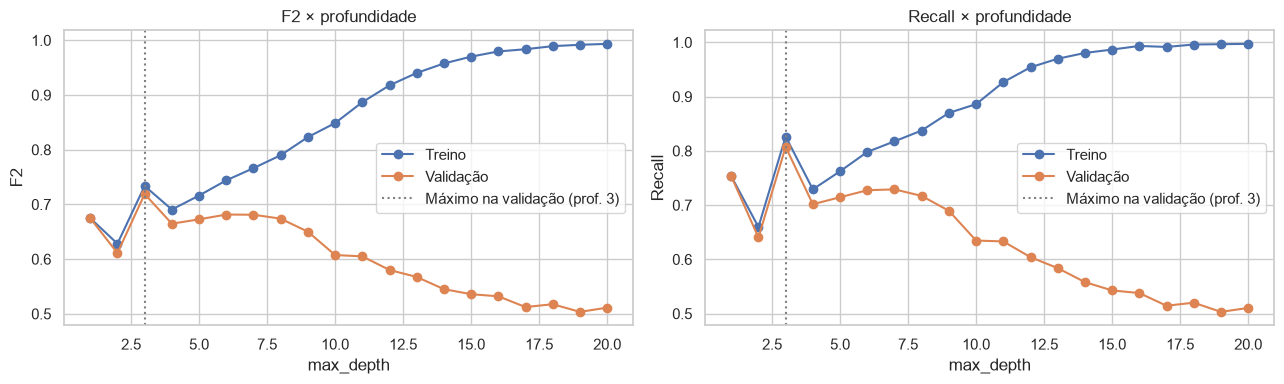

max_depth,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
F2 treino,0.675,0.628,0.734,0.691,0.716,0.744,0.766,0.790,0.823,0.849,0.887,0.918,0.940,0.958,0.970,0.980,0.984,0.989,0.992,0.993
F2 validação,0.675,0.611,0.719,0.665,0.673,0.681,0.681,0.674,0.650,0.607,0.605,0.580,0.567,0.545,0.536,0.532,0.512,0.518,0.504,0.511
Recall treino,0.753,0.660,0.826,0.729,0.762,0.798,0.818,0.838,0.870,0.886,0.927,0.954,0.970,0.980,0.987,0.993,0.992,0.996,0.997,0.997
Recall validação,0.753,0.640,0.807,0.702,0.715,0.727,0.729,0.717,0.690,0.635,0.633,0.604,0.584,0.558,0.543,0.538,0.515,0.520,0.503,0.510


In [13]:
profundidades = list(range(1, 21))
curva = []
for prof in profundidades:
    modelo = DecisionTreeClassifier(
        max_depth=prof, random_state=SEED,
        criterion=melhores_a["modelo__criterion"],
        class_weight=melhores_a["modelo__class_weight"],
    )
    r = cross_validate(montar_pipeline(modelo), X_treino, y_treino, cv=CV,
                       scoring={"f2": F2, "recall": "recall"}, return_train_score=True, n_jobs=-1)
    curva.append({
        "max_depth": prof,
        "F2 treino": r["train_f2"].mean(), "F2 validação": r["test_f2"].mean(),
        "Recall treino": r["train_recall"].mean(), "Recall validação": r["test_recall"].mean(),
    })
curva = pd.DataFrame(curva).set_index("max_depth")

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
for eixo, metrica in zip(eixos, ["F2", "Recall"]):
    eixo.plot(curva.index, curva[f"{metrica} treino"], marker="o", label="Treino")
    eixo.plot(curva.index, curva[f"{metrica} validação"], marker="o", label="Validação")
    eixo.axvline(curva[f"{metrica} validação"].idxmax(), color="gray", linestyle=":",
                 label=f"Máximo na validação (prof. {curva[f'{metrica} validação'].idxmax()})")
    eixo.set_xlabel("max_depth")
    eixo.set_ylabel(metrica)
    eixo.set_title(f"{metrica} × profundidade")
    eixo.legend()
plt.tight_layout()
plt.show()
display(curva.round(3).T)

### 5.3 Pós-poda por complexidade de custo (`ccp_alpha`)

A pós-poda cresce a árvore completa e depois remove os ramos que menos reduzem a impureza em relação ao número de folhas que acrescentam. O parâmetro `ccp_alpha` controla essa troca: quanto maior, mais agressiva a poda.

1. Calculamos o caminho de poda (`cost_complexity_pruning_path`) da árvore completa, com o mesmo `criterion` e `class_weight` da pré-poda para uma comparação justa. Esse caminho fornece os valores de alpha em que a árvore muda.
2. Esse caminho só define a **lista de candidatos** de alpha. A escolha do alpha é feita por validação cruzada, com o pré-processamento e a árvore reajustados em cada rodada.

Alphas distintos no caminho de poda: 513 | candidatos avaliados: 49


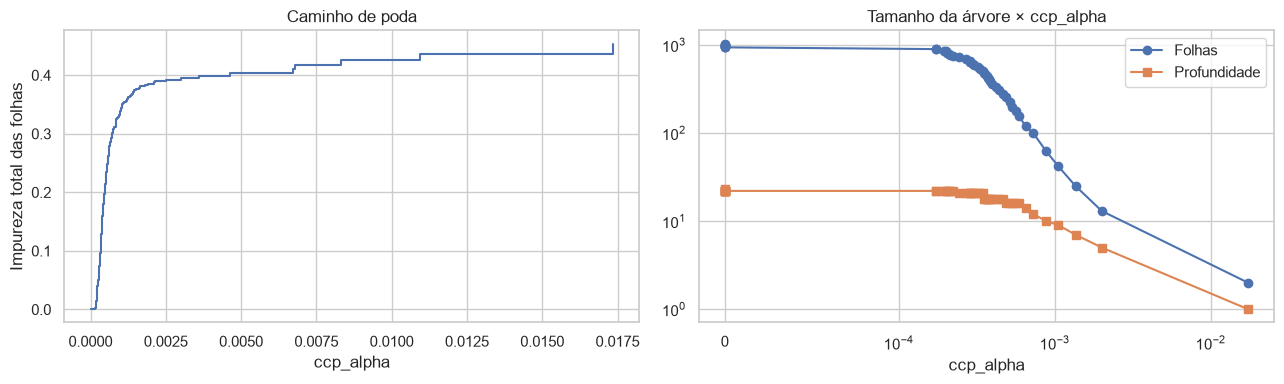

In [14]:
modelo_base_pos = DecisionTreeClassifier(
    random_state=SEED,
    criterion=melhores_a["modelo__criterion"],
    class_weight=melhores_a["modelo__class_weight"],
)

prep_caminho = clone(PREPROCESSADOR_TEMPLATE).fit(X_treino)
caminho = clone(modelo_base_pos).cost_complexity_pruning_path(prep_caminho.transform(X_treino), y_treino)
alphas_caminho, impurezas = caminho.ccp_alphas, caminho.impurities

# Remove o último alpha (árvore só com a raiz) e amostra 50 candidatos por quantis
alphas_candidatos = np.unique(np.quantile(alphas_caminho[:-1], np.linspace(0, 1, 50)))
print(f"Alphas distintos no caminho de poda: {len(alphas_caminho)} | candidatos avaliados: {len(alphas_candidatos)}")

# Estrutura da árvore para cada alpha (descritivo, no treino completo)
estrutura = []
Xp_caminho = prep_caminho.transform(X_treino)
for alpha in alphas_candidatos:
    arv = clone(modelo_base_pos).set_params(ccp_alpha=alpha).fit(Xp_caminho, y_treino)
    estrutura.append({"ccp_alpha": alpha, "folhas": arv.get_n_leaves(), "profundidade": arv.get_depth()})
estrutura = pd.DataFrame(estrutura)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
eixos[0].plot(alphas_caminho[:-1], impurezas[:-1], drawstyle="steps-post")
eixos[0].set_xlabel("ccp_alpha")
eixos[0].set_ylabel("Impureza total das folhas")
eixos[0].set_title("Caminho de poda")
eixos[1].plot(estrutura["ccp_alpha"], estrutura["folhas"], marker="o", label="Folhas")
eixos[1].plot(estrutura["ccp_alpha"], estrutura["profundidade"], marker="s", label="Profundidade")
eixos[1].set_xscale("symlog", linthresh=1e-4)
eixos[1].set_yscale("log")
eixos[1].set_xlabel("ccp_alpha")
eixos[1].set_title("Tamanho da árvore × ccp_alpha")
eixos[1].legend()
plt.tight_layout()
plt.show()

Busca de ccp_alpha: 49 valores em 6.4 s
ccp_alpha escolhido: 0.000729 | F2 (val): 0.6644
Árvore pós-podada: profundidade 12, 100 folhas


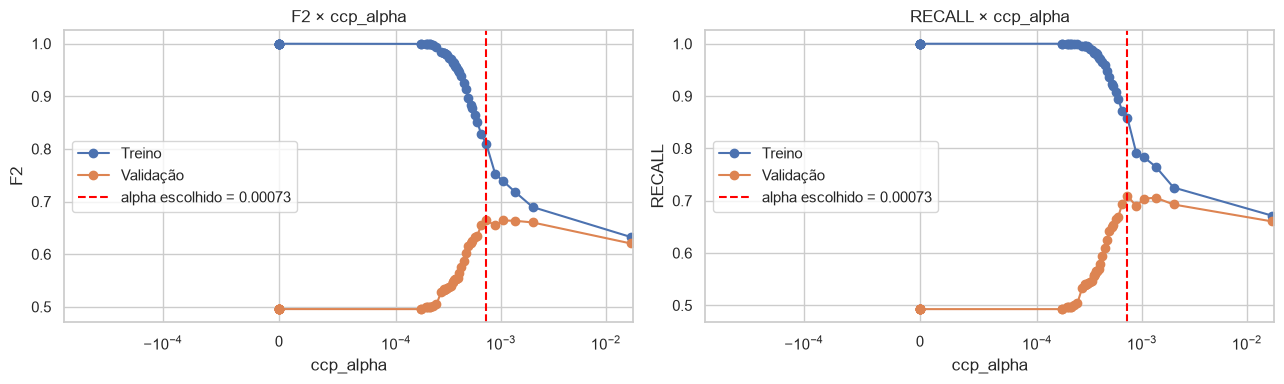

In [15]:
busca_pos = GridSearchCV(
    montar_pipeline(modelo_base_pos),
    {"modelo__ccp_alpha": alphas_candidatos},
    scoring=METRICAS, refit=METRICA_BUSCA, cv=CV, n_jobs=-1, return_train_score=True
)
inicio = time.perf_counter()
busca_pos.fit(X_treino, y_treino)
tempo_pos = time.perf_counter() - inicio

registrar_busca("AD pós-poda", busca_pos, tempo_pos)
ad_pos = busca_pos.best_estimator_
alpha_escolhido = busca_pos.best_params_["modelo__ccp_alpha"]

print(f"Busca de ccp_alpha: {len(alphas_candidatos)} valores em {tempo_pos:.1f} s")
print(f"ccp_alpha escolhido: {alpha_escolhido:.6f} | F2 (val): {busca_pos.best_score_:.4f}")
print(f"Árvore pós-podada: profundidade {ad_pos[-1].get_depth()}, {ad_pos[-1].get_n_leaves()} folhas")

res_pos = pd.DataFrame(busca_pos.cv_results_)
fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
for eixo, metrica in zip(eixos, ["f2", "recall"]):
    eixo.plot(res_pos["param_modelo__ccp_alpha"].astype(float), res_pos[f"mean_train_{metrica}"], marker="o", label="Treino")
    eixo.plot(res_pos["param_modelo__ccp_alpha"].astype(float), res_pos[f"mean_test_{metrica}"], marker="o", label="Validação")
    eixo.axvline(alpha_escolhido, color="red", linestyle="--", label=f"alpha escolhido = {alpha_escolhido:.5f}")
    eixo.set_xscale("symlog", linthresh=1e-4)
    eixo.set_xlabel("ccp_alpha")
    eixo.set_ylabel(metrica.upper())
    eixo.set_title(f"{metrica.upper()} × ccp_alpha")
    eixo.legend()
plt.tight_layout()
plt.show()

### 5.4 Comparação: sem poda × pré-poda × pós-poda

Comparamos as três árvores pelas métricas médias da validação cruzada, pelo gap treino-validação, pelo tamanho e pelo tempo de busca. Para as duas árvores podadas, também aplicamos o ajuste de limiar (recall-alvo de 80%).

**Critério de escolha da árvore final:** maior F2 na validação; se a diferença for menor que 0,005, preferimos a árvore com menos folhas (mais simples e interpretável).

--- COMPARAÇÃO DAS ÁRVORES (VALIDAÇÃO CRUZADA) ---


,recall (val),precision (val),f1 (val),f2 (val),roc_auc (val),pr_auc (val),gap recall (treino-val),gap acurácia (treino-val),tempo (s),profundidade,folhas
Regressão logística,0.729,0.583,0.648,0.694,0.798,0.670,0.006,0.004,6.463,NaN,NaN
AD sem restrições,0.492,0.501,0.496,0.494,0.611,0.427,0.507,0.354,0.493,25.0,932.0
AD pré-poda,0.806,0.508,0.623,0.722,0.736,0.556,0.014,0.004,145.784,3.0,8.0
AD pós-poda,0.710,0.530,0.607,0.664,0.717,0.552,0.149,0.117,6.426,12.0,100.0


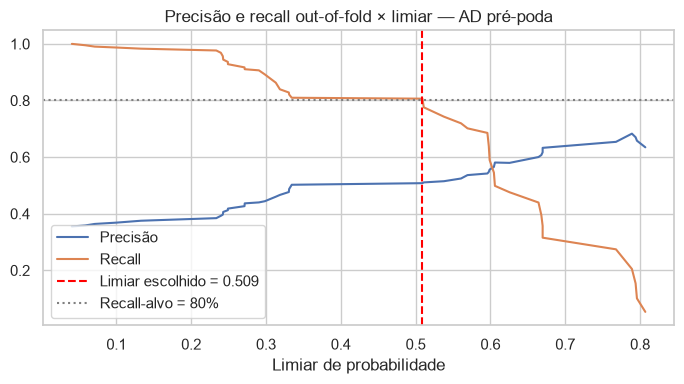

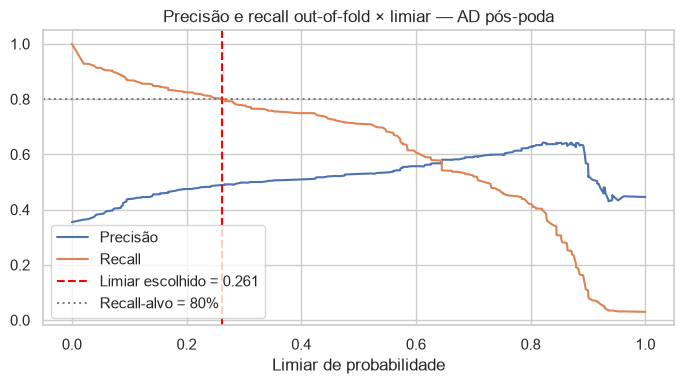

--- AJUSTE DE LIMIAR (OUT-OF-FOLD NO TREINO) ---


,limiar,recall (limiar),precisão (limiar),F1 (limiar),F2 (limiar),"recall (0,5)","precisão (0,5)"
Regressão logística,0.435,0.801,0.550,0.652,0.734,0.729,0.583
AD pré-poda,0.509,0.806,0.508,0.623,0.722,0.806,0.508
AD pós-poda,0.261,0.802,0.489,0.607,0.711,0.710,0.530


In [16]:
nomes_ad = ["AD sem restrições", "AD pré-poda", "AD pós-poda"]
comparacao_ad = tabela_cv(["Regressão logística"] + nomes_ad)
comparacao_ad["profundidade"] = [np.nan, ad_livre[-1].get_depth(), ad_pre[-1].get_depth(), ad_pos[-1].get_depth()]
comparacao_ad["folhas"] = [np.nan, ad_livre[-1].get_n_leaves(), ad_pre[-1].get_n_leaves(), ad_pos[-1].get_n_leaves()]
print("--- COMPARAÇÃO DAS ÁRVORES (VALIDAÇÃO CRUZADA) ---")
display(comparacao_ad)

LIMIAR_AD_PRE, _ = escolher_limiar("AD pré-poda", clone(ad_pre))
LIMIAR_AD_POS, _ = escolher_limiar("AD pós-poda", clone(ad_pos))
print("--- AJUSTE DE LIMIAR (OUT-OF-FOLD NO TREINO) ---")
display(tabela_limiares(["Regressão logística", "AD pré-poda", "AD pós-poda"]))

In [17]:
f2_pre = RESULTADOS_CV["AD pré-poda"]["f2 (val)"]
f2_pos = RESULTADOS_CV["AD pós-poda"]["f2 (val)"]

if abs(f2_pre - f2_pos) < 0.005:
    usar_pre = ad_pre[-1].get_n_leaves() <= ad_pos[-1].get_n_leaves()
    motivo = "F2 equivalente; escolhida a árvore com menos folhas"
else:
    usar_pre = f2_pre > f2_pos
    motivo = "maior F2 na validação"

NOME_AD_FINAL = "AD pré-poda" if usar_pre else "AD pós-poda"
AD_FINAL = ad_pre if usar_pre else ad_pos
LIMIAR_AD = LIMIAR_AD_PRE if usar_pre else LIMIAR_AD_POS

print(f"Árvore final: {NOME_AD_FINAL} ({motivo})")
print(f"F2 val — pré: {f2_pre:.4f} | pós: {f2_pos:.4f}")
print(f"Profundidade {AD_FINAL[-1].get_depth()}, {AD_FINAL[-1].get_n_leaves()} folhas, limiar = {LIMIAR_AD:.3f}")

Árvore final: AD pré-poda (maior F2 na validação)
F2 val — pré: 0.7215 | pós: 0.6644
Profundidade 3, 8 folhas, limiar = 0.509


### 5.5 Extração de regras SE-ENTÃO

A árvore final já está ajustada no treino completo. Como o pré-processamento manteve as variáveis na escala original e codificou as categorias de forma ordinal, as condições são traduzidas direto para a linguagem do negócio:

- `tipo_contrato <= 0,5` vira `tipo_contrato ∈ {AUSENTE, MENSAL}`;
- `fibra_optica <= 0,5` vira `fibra_optica = 0`;
- `chamados_90d <= 2,5` vira `chamados_90d <= 2`, porque o atributo é inteiro;
- condições repetidas sobre o mesmo atributo ao longo do caminho são unidas em um único intervalo.

Para cada regra, informamos o **suporte** (quantos clientes do treino ela cobre) e a **taxa de churn real** desses clientes. A previsão da regra é a classe majoritária do nó, ponderada por `class_weight` quando ele é usado.

In [18]:
from sklearn.tree import export_text

CODIGOS = {
    "tipo_contrato": {-1: "AUSENTE", 0: "MENSAL", 1: "ANUAL", 2: "BIENAL"},
    "forma_pagamento": {-1: "AUSENTE", 0: "BOLETO", 1: "CARTAO", 2: "PIX"},
}
BINARIAS = {"fibra_optica", "debito_automatico"}
INTEIRAS = {"atrasos_6m", "chamados_90d", "tempo_cliente_meses"}


def descrever_intervalo(atributo, minimo, maximo):
    """Traduz o intervalo (minimo, maximo] acumulado no caminho para linguagem de negócio."""
    if atributo in CODIGOS:
        categorias = [nome for cod, nome in CODIGOS[atributo].items() if minimo < cod <= maximo]
        return f"{atributo} ∈ {{{', '.join(categorias)}}}"
    if atributo in BINARIAS:
        return f"{atributo} = {1 if minimo >= 0 else 0}"
    if atributo in INTEIRAS:
        de = int(np.floor(minimo)) + 1 if np.isfinite(minimo) else None
        ate = int(np.floor(maximo)) if np.isfinite(maximo) else None
        if de is not None and ate is not None:
            return f"{atributo} = {de}" if de == ate else f"{de} <= {atributo} <= {ate}"
        return f"{atributo} >= {de}" if de is not None else f"{atributo} <= {ate}"
    partes = []
    if np.isfinite(minimo):
        partes.append(f"> R$ {minimo:.2f}")
    if np.isfinite(maximo):
        partes.append(f"<= R$ {maximo:.2f}")
    return f"{atributo} " + " e ".join(partes)


def extrair_regras(pipeline, X, y, profundidade_max=None):
    """Percorre a árvore até `profundidade_max` e mede suporte e churn real de cada regra.

    As condições sobre um mesmo atributo são unidas em um único intervalo
    (ex.: chamados >= 2 E chamados >= 3  →  chamados >= 3).
    """
    arvore = pipeline.named_steps["modelo"].tree_
    Xp = pipeline.named_steps["prep"].transform(X)
    nomes, valores, alvo = list(Xp.columns), Xp.to_numpy(dtype=float), y.to_numpy()
    regras = []

    def visitar(no, mascara, limites, profundidade):
        folha = arvore.children_left[no] == -1
        if folha or profundidade == profundidade_max:
            n = int(mascara.sum())
            condicoes = [descrever_intervalo(a, lo, hi) for a, (lo, hi) in limites.items()]
            regras.append({
                "regra": "SE " + " E ".join(condicoes),
                "previsão": "CHURN" if np.argmax(arvore.value[no][0]) == 1 else "NÃO CHURN",
                "clientes": n,
                "suporte (%)": 100 * n / len(alvo),
                "churn real (%)": 100 * alvo[mascara].mean() if n else np.nan,
            })
            return
        j, t = arvore.feature[no], arvore.threshold[no]
        atributo = nomes[j]
        lo, hi = limites.get(atributo, (-np.inf, np.inf))
        vai_esquerda = valores[:, j] <= t
        visitar(arvore.children_left[no], mascara & vai_esquerda,
                {**limites, atributo: (lo, min(hi, t))}, profundidade + 1)
        visitar(arvore.children_right[no], mascara & ~vai_esquerda,
                {**limites, atributo: (max(lo, t), hi)}, profundidade + 1)

    visitar(0, np.ones(len(alvo), dtype=bool), {}, 0)
    return (pd.DataFrame(regras)
            .sort_values("churn real (%)", ascending=False)
            .reset_index(drop=True)
            .round(1))


def imprimir_regras(regras):
    for _, r in regras.iterrows():
        print(f"{r['regra']}\n    ENTÃO {r['previsão']}  "
              f"[{r['clientes']} clientes, {r['suporte (%)']}% do treino, churn real {r['churn real (%)']}%]\n")


PROFUNDIDADE_REGRAS = 3
regras_topo = extrair_regras(AD_FINAL, X_treino, y_treino, profundidade_max=PROFUNDIDADE_REGRAS)
print(f"--- REGRAS DO TOPO DA ÁRVORE (ATÉ PROFUNDIDADE {PROFUNDIDADE_REGRAS}) — {NOME_AD_FINAL} ---")
print(f"Taxa de churn geral no treino: {100 * y_treino.mean():.1f}%\n")
imprimir_regras(regras_topo)

--- REGRAS DO TOPO DA ÁRVORE (ATÉ PROFUNDIDADE 3) — AD pré-poda ---
Taxa de churn geral no treino: 35.5%

SE tipo_contrato ∈ {AUSENTE, MENSAL} E chamados_90d >= 3
    ENTÃO CHURN  [454 clientes, 13.0% do treino, churn real 68.3%]

SE tipo_contrato ∈ {AUSENTE, MENSAL} E chamados_90d = 2
    ENTÃO CHURN  [500 clientes, 14.3% do treino, churn real 52.6%]

SE tipo_contrato ∈ {AUSENTE, MENSAL} E chamados_90d <= 1 E tempo_cliente_meses <= 29
    ENTÃO CHURN  [631 clientes, 18.1% do treino, churn real 45.3%]

SE tipo_contrato ∈ {ANUAL, BIENAL} E tempo_cliente_meses <= 22 E fibra_optica = 1
    ENTÃO CHURN  [462 clientes, 13.2% do treino, churn real 37.9%]

SE tipo_contrato ∈ {AUSENTE, MENSAL} E chamados_90d <= 1 E tempo_cliente_meses >= 30
    ENTÃO NÃO CHURN  [375 clientes, 10.7% do treino, churn real 20.0%]

SE tipo_contrato ∈ {ANUAL, BIENAL} E tempo_cliente_meses >= 23 E chamados_90d >= 3
    ENTÃO NÃO CHURN  [150 clientes, 4.3% do treino, churn real 20.0%]

SE tipo_contrato ∈ {ANUAL, BIEN

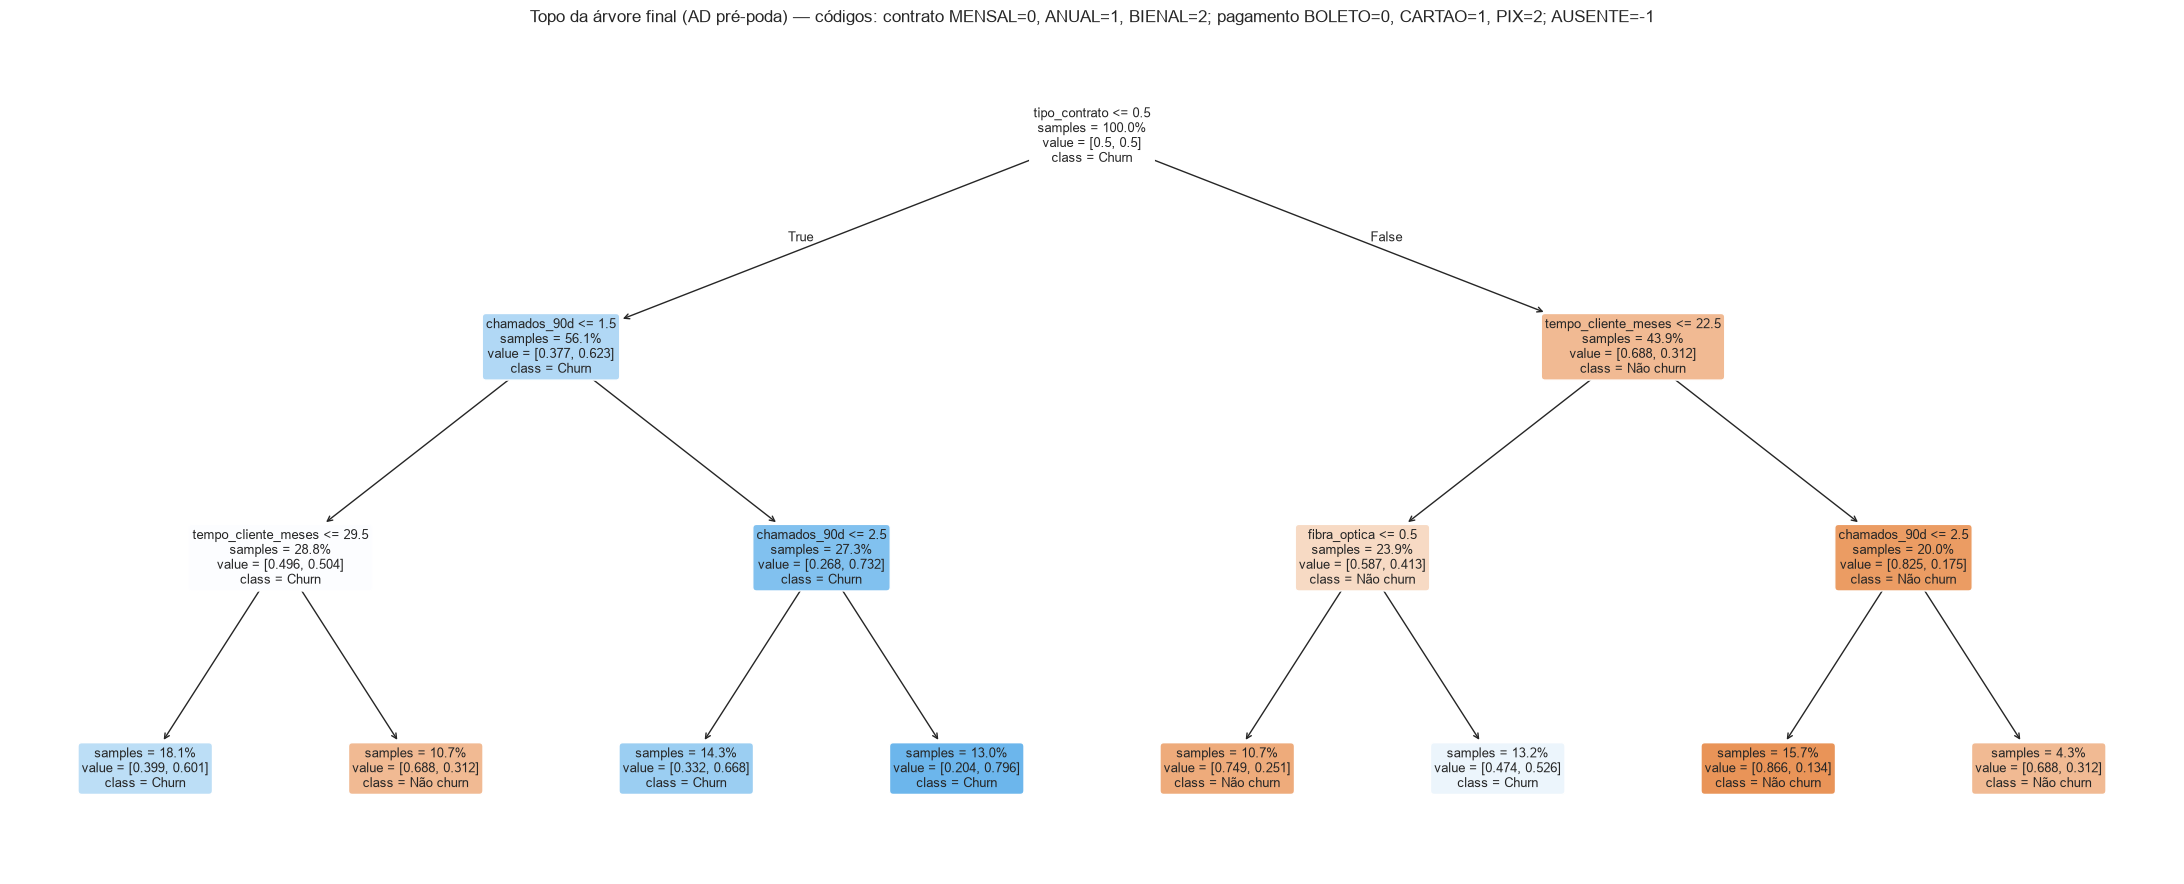

In [19]:
fig, eixo = plt.subplots(figsize=(22, 9))
plot_tree(
    AD_FINAL.named_steps["modelo"], max_depth=PROFUNDIDADE_REGRAS, feature_names=ATRIBUTOS,
    class_names=["Não churn", "Churn"], filled=True, rounded=True, impurity=False,
    proportion=True, fontsize=9, ax=eixo
)
eixo.set_title(f"Topo da árvore final ({NOME_AD_FINAL}) — códigos: contrato MENSAL=0, ANUAL=1, BIENAL=2; "
               f"pagamento BOLETO=0, CARTAO=1, PIX=2; AUSENTE=-1")
plt.tight_layout()
plt.show()

#### 5.5.1 Folhas de maior e menor risco

Além do topo, listamos as folhas completas da árvore com maior taxa de churn (perfis prioritários para retenção) e as de menor risco, considerando apenas folhas com pelo menos 1% dos clientes do treino, para evitar regras baseadas em poucos casos.

In [20]:
regras_folhas = extrair_regras(AD_FINAL, X_treino, y_treino)
relevantes = regras_folhas[regras_folhas["suporte (%)"] >= 1.0]
print(f"Folhas: {len(regras_folhas)} no total, {len(relevantes)} com suporte ≥ 1%\n")

print("--- 5 PERFIS DE MAIOR RISCO ---\n")
imprimir_regras(relevantes.head(5))
print("--- 5 PERFIS DE MENOR RISCO ---\n")
imprimir_regras(relevantes.tail(5).iloc[::-1])

Folhas: 8 no total, 8 com suporte ≥ 1%

--- 5 PERFIS DE MAIOR RISCO ---

SE tipo_contrato ∈ {AUSENTE, MENSAL} E chamados_90d >= 3
    ENTÃO CHURN  [454 clientes, 13.0% do treino, churn real 68.3%]

SE tipo_contrato ∈ {AUSENTE, MENSAL} E chamados_90d = 2
    ENTÃO CHURN  [500 clientes, 14.3% do treino, churn real 52.6%]

SE tipo_contrato ∈ {AUSENTE, MENSAL} E chamados_90d <= 1 E tempo_cliente_meses <= 29
    ENTÃO CHURN  [631 clientes, 18.1% do treino, churn real 45.3%]

SE tipo_contrato ∈ {ANUAL, BIENAL} E tempo_cliente_meses <= 22 E fibra_optica = 1
    ENTÃO CHURN  [462 clientes, 13.2% do treino, churn real 37.9%]

SE tipo_contrato ∈ {AUSENTE, MENSAL} E chamados_90d <= 1 E tempo_cliente_meses >= 30
    ENTÃO NÃO CHURN  [375 clientes, 10.7% do treino, churn real 20.0%]

--- 5 PERFIS DE MENOR RISCO ---

SE tipo_contrato ∈ {ANUAL, BIENAL} E tempo_cliente_meses >= 23 E chamados_90d <= 2
    ENTÃO NÃO CHURN  [548 clientes, 15.7% do treino, churn real 7.8%]

SE tipo_contrato ∈ {ANUAL, BIEN

### 5.6 Importância dos atributos

Comparamos duas medidas:

- **Importância por impureza** (`feature_importances_`): quanto cada atributo reduziu a impureza nas divisões da árvore final. É rápida, mas medida no próprio treino e enviesada a favor de atributos com muitos valores distintos.
- **Importância por permutação**: queda do **recall** na validação quando os valores de um atributo são embaralhados. Calculamos em cada uma das 5 partes da validação cruzada, com o modelo treinado nas outras 4, e tiramos a média. Isso mede o efeito real na métrica principal **sem usar o teste**.

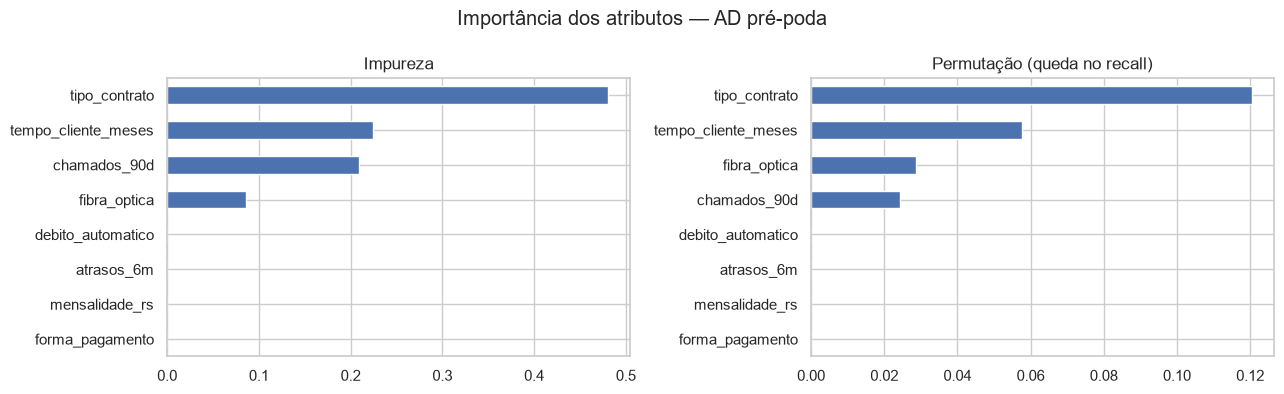

,Impureza,Permutação (queda no recall)
tipo_contrato,0.4806,0.1205
tempo_cliente_meses,0.2245,0.0576
chamados_90d,0.2087,0.0244
fibra_optica,0.0862,0.0286
debito_automatico,0.0000,0.0000
atrasos_6m,0.0000,0.0000
mensalidade_rs,0.0000,0.0000
forma_pagamento,0.0000,0.0000


In [21]:
from sklearn.inspection import permutation_importance


def importancia_permutacao_cv(pipeline, scoring="recall", n_repeats=10):
    importancias = []
    for idx_treino, idx_val in CV.split(X_treino, y_treino):
        modelo = clone(pipeline).fit(X_treino.iloc[idx_treino], y_treino.iloc[idx_treino])
        r = permutation_importance(
            modelo, X_treino.iloc[idx_val], y_treino.iloc[idx_val],
            scoring=scoring, n_repeats=n_repeats, random_state=SEED, n_jobs=-1
        )
        importancias.append(r.importances_mean)
    return pd.Series(np.mean(importancias, axis=0), index=X_treino.columns)


importancia_ad = pd.DataFrame({
    "Impureza": pd.Series(AD_FINAL.named_steps["modelo"].feature_importances_, index=ATRIBUTOS),
    "Permutação (queda no recall)": importancia_permutacao_cv(AD_FINAL),
}).sort_values("Impureza", ascending=False)

fig, eixos = plt.subplots(1, 2, figsize=(13, 4))
for eixo, coluna in zip(eixos, importancia_ad.columns):
    importancia_ad[coluna].sort_values().plot.barh(ax=eixo)
    eixo.set_title(coluna)
fig.suptitle(f"Importância dos atributos — {NOME_AD_FINAL}")
plt.tight_layout()
plt.show()
display(importancia_ad.round(4))

### 5.7 Conclusões parciais da Árvore de Decisão

**Referências (seção 4).** Os modelos triviais confirmam o problema das métricas isoladas: "sempre não churn" tem 64,5% de acurácia e recall zero; "sempre churn" tem recall 1,0 e F2 = 0,733, porém precisão de apenas 35,5% (a prevalência). A regressão logística atinge F2 = 0,694 e ROC-AUC = 0,798, sem overfitting (gap ≈ 0,01).

**Overfitting da árvore livre.** Sem restrições, a árvore chega a 25 níveis e 932 folhas: recall de ~1,0 no treino contra 0,49 na validação (gap de 0,51). É o pior modelo testado, inclusive abaixo da regressão logística.

**Pré-poda × pós-poda.**

| | F2 (val) | Recall (val) | Precisão (val) | Gap recall | Folhas |
|---|---|---|---|---|---|
| Pré-poda (`max_depth=3`, `class_weight=balanced`) | **0,722** | **0,806** | 0,508 | **0,014** | **8** |
| Pós-poda (`ccp_alpha≈0,00073`) | 0,664 | 0,710 | 0,530 | 0,149 | 100 |

- A **pré-poda venceu** em F2, recall, gap e simplicidade. A curva de validação mostra o pico em `max_depth = 3`; a partir de 6–7 níveis o treino continua subindo e a validação cai.
- A pós-poda mantém uma árvore 12× maior e ainda com gap de ~0,15. Com `class_weight=balanced`, o alpha que maximiza o F2 é pequeno e poda pouco.
- Na etapa A, vários hiperparâmetros (`min_samples_leaf`, `min_samples_split`) **empataram**: com profundidade 3, as folhas já têm centenas de clientes e esses limites não chegam a atuar. Na etapa B, `max_leaf_nodes=8` e `max_features=0.75` trouxeram um ganho pequeno (F2 0,719 → 0,722).
- O `class_weight="balanced"` foi decisivo: todas as melhores combinações o utilizam.

**Ajuste de limiar.** Para o recall-alvo de 80%, a árvore pré-podada já opera praticamente no corte padrão (limiar 0,509), pois tem só 8 folhas e, portanto, poucas probabilidades distintas. Com o mesmo recall (~0,80), a **regressão logística tem precisão maior** (0,55 contra 0,51), coerente com o seu ROC-AUC superior (0,80 contra 0,74). A árvore ganha em interpretabilidade; o XGBoost deverá mostrar se é possível superar ambos.

**Regras e atributos de risco.** O tipo de contrato é a primeira divisão e o atributo mais importante (48% da importância por impureza; maior queda de recall na permutação), seguido de tempo de cliente e chamados nos últimos 90 dias; a fibra óptica aparece nos clientes com contrato anual/bienal recentes. O perfil de maior risco é **contrato mensal com 3 ou mais chamados em 90 dias** (68% de churn, contra 35,5% na base). O de menor risco é **contrato anual/bienal, cliente há 23 meses ou mais e até 2 chamados** (7,8%). Mensalidade, atrasos, forma de pagamento e débito automático não foram usados pela árvore de profundidade 3: o modelo prioriza os sinais mais fortes, o que não significa que esses atributos sejam irrelevantes; a análise do XGBoost dirá se eles contribuem.